# Modelling and Small-Data Machine Learning Pipeline for LMD

**objective:** Prepare the processed dataset for ML, Perform scaling, transformations, feature selection, multicolinearity checks, applying baseline linear regression, residual analysis and validation suitable for small data. 

In [2]:
# import libraries

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import statsmodels.api as sm




# Load data and selecting features


In [3]:
# Loading the dataset

df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")


target = "porosity_%" # change to other targets as needed

# use core process parameters  as inputs (avoid LED/VED to reduce multicolinearity)
features = ["Power","Speed", "Feed"] 

X = df[features].copy()
y = df[target].copy()

print("Features shape: ", X.shape)
print("Target shape")

Features shape:  (89, 3)
Target shape


## Multicollinearity Check (VIF Analysis)
When two or more predictor (input) variables in a regression model carry almost the same information because they are strongly linearly correlated with each other.

Variance Inflation Factor (VIF): for each predictor , fit a regression of that predictor on all the others and compute.

Interpretation guidance :

VIF > 10 → severe multicollinearity, remove or combine features

VIF 5–10 → moderate, monitor

VIF < 5 → acceptable

In [4]:
#Check for multicollinearirty
# #from statsmodels.stats.outliers_influence import variance_inflation_factor
def compute_vif(X):
    vif_df = pd.DataFrame()
    vif_df["feature"] = X.columns
    vif_df["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(len(X.columns))
    ]
    return vif_df

compute_vif(X)


,feature,VIF
0,Power,14.227862
1,Speed,10.482437
2,Feed,5.676945


# Train/test split and scaling


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

print("Train size: ", X_train_scaled.shape[0], "| Test size:", X_test_scaled.shape[0])

Train size:  71 | Test size: 18


# Fit linear regression model

In [6]:

# Define models

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predictions

y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)
# --- IGNORE ---



## Model coefficients and interpretation


In [7]:
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lr_model.coef_
})

coef_df["intercept"] = lr_model.intercept_  
print(coef_df)  


  feature  coefficient  intercept
0   Power    -0.119660   0.350563
1   Speed    -0.220476   0.350563
2    Feed     0.175098   0.350563


## Performance Metrics

In [8]:
def evaluate_model(y_true, y_pred, dataset_name = ""):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = lr_model.score(X_test_scaled, y_test)
    
    print(f"Evaluation Metrics for {dataset_name} dataset:")
    print(f"RMSE: {rmse:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R^2: {r2:.4f}")
    print("\n")
    
    return {"RMSE": rmse, "MSE": mse, "MAE": mae, "R2": r2}

train_metrics = evaluate_model(y_train, y_train_pred, dataset_name="Training Set")
test_metrics = evaluate_model(y_test, y_test_pred, dataset_name="Testing Set")         

Evaluation Metrics for Training Set dataset:
RMSE: 0.3772
MSE: 0.1423
MAE: 0.2273
R^2: -5.1343


Evaluation Metrics for Testing Set dataset:
RMSE: 0.3552
MSE: 0.1262
MAE: 0.3132
R^2: -5.1343




# Cross validationnfor robust estimates



In [57]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Note: cross_val_score uses negative MSE by default for scoring
"""
cv_rmse = -cross_val_score(
    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True
)   
cv_r2 = cross_val_score(
    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="r2", return_train_score=True
)

print("Cross-Validation Results:")
print(f"Average Train RMSE: {np.mean(np.sqrt(cv_rmse['train_score'])):.4f}")
print(f"Average Test RMSE: {np.mean(np.sqrt(cv_rmse['test_score'])):.4f}")
print(f"Average Train R^2: {np.mean(cv_r2['train_score']):.4f}")
print(f"Average Test R^2: {np.mean(cv_r2['test_score']):.4f}")  
"""

'\ncv_rmse = -cross_val_score(\n    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True\n)   \ncv_r2 = cross_val_score(\n    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="r2", return_train_score=True\n)\n\nprint("Cross-Validation Results:")\nprint(f"Average Train RMSE: {np.mean(np.sqrt(cv_rmse[\'train_score\'])):.4f}")\nprint(f"Average Test RMSE: {np.mean(np.sqrt(cv_rmse[\'test_score\'])):.4f}")\nprint(f"Average Train R^2: {np.mean(cv_r2[\'train_score\']):.4f}")\nprint(f"Average Test R^2: {np.mean(cv_r2[\'test_score\']):.4f}")  \n'

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Note: cross_val_score uses neg_mean_squared_error
cv_rmse = -cross_val_score(lr_model, scaler.fit_transform(X), y, cv=cv, scoring="neg_root_mean_squared_error")
cv_r2 = cross_val_score(lr_model, scaler.fit_transform(X), y, cv=cv, scoring="r2")

print(f"5-Fold CV RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")
print(f"5-Fold CV R²:   {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")


5-Fold CV RMSE: 0.3627 ± 0.1553
5-Fold CV R²:   -0.6408 ± 2.0913


# Model Diagnostics: Checking Linear regression Asssumptions


In [11]:
# Compute resuduals
residuals_train = y_train - y_train_pred
residuals_test = y_test - y_test_pred


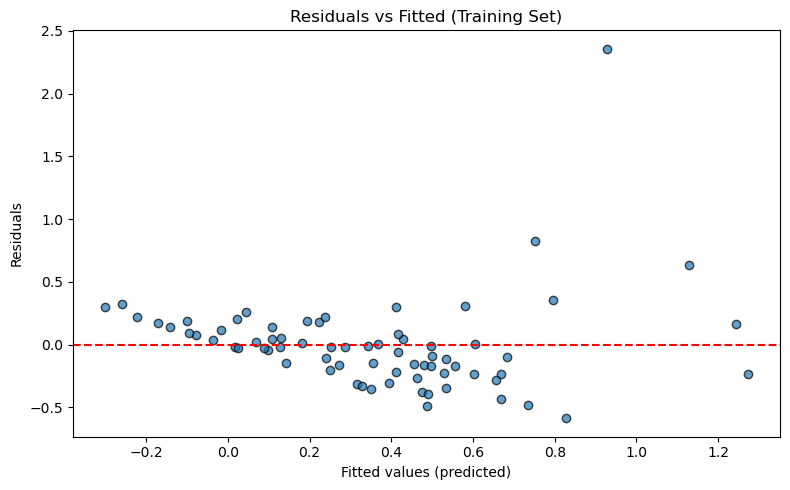

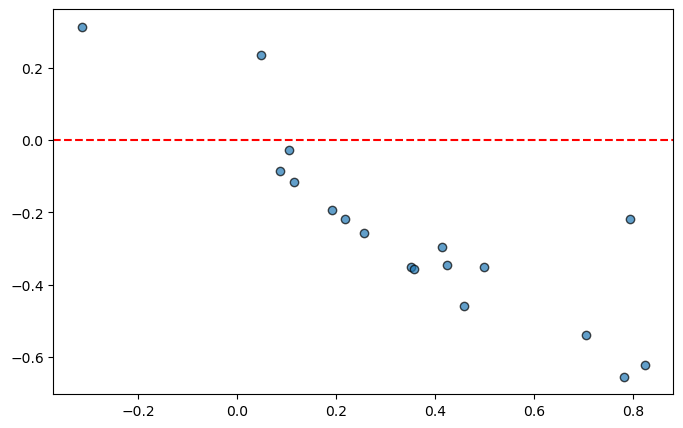

In [12]:
# Residuals vs Fitted
plt.figure(figsize=(8, 5))
plt.scatter(y_train_pred, residuals_train, alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted)")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (Training Set)")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals_test, alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")


What to look for:

Linearity: residuals should scatter randomly around zero with no clear curve.

Homoscedasticity: spread of residuals should be roughly constant across fitted values (no funnel shape).

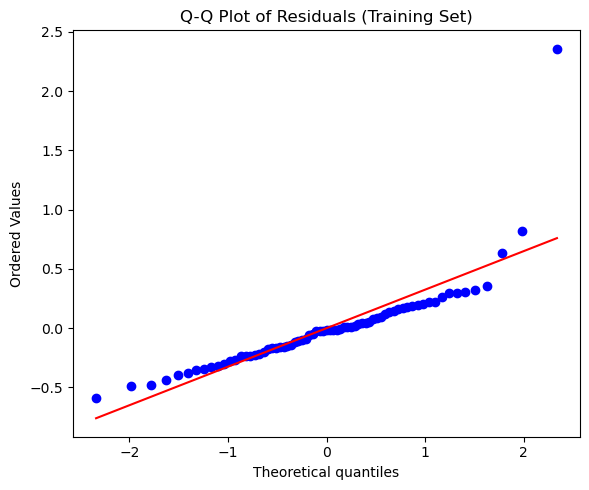

In [34]:
#Q-Q Plot (Normality of Residuals)
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(residuals_train, dist="norm", plot=ax)
ax.set_title("Q-Q Plot of Residuals (Training Set)")
plt.tight_layout()
plt.show()


What to look for:

Points should fall approximately along the diagonal line.

Deviations at the tails suggest heavy tails or skewness.




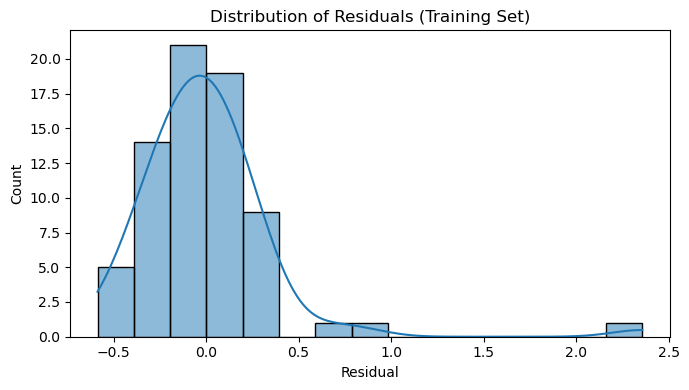

In [35]:
# Histogram of Residuals
plt.figure(figsize=(7, 4))
sns.histplot(residuals_train, kde=True, bins=15)
plt.xlabel("Residual")
plt.title("Distribution of Residuals (Training Set)")
plt.tight_layout()
plt.show()
#plt.xlabel("Fitted values (predicted)")
#plt.ylabel("Residuals")
#plt.title("Residuals vs Fitted (Testing Set)")
#plt.tight_layout()
#plt.show()          

What to look for: Approximately bell-shaped and centred near zero.

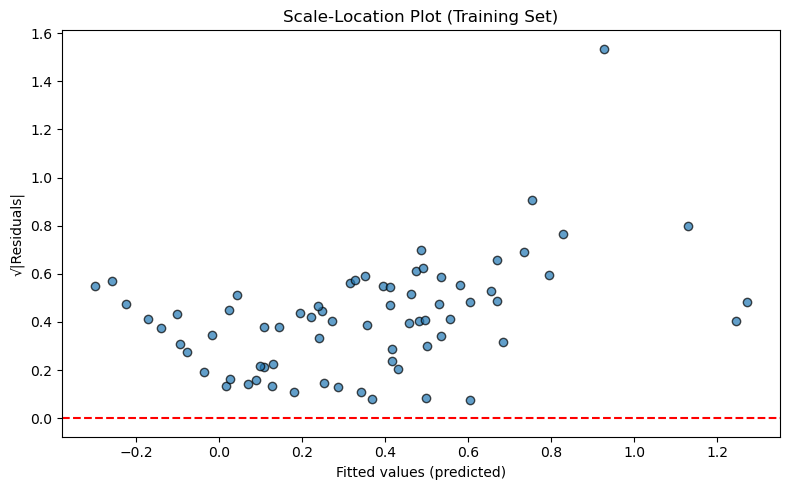

In [36]:
# Scale-Location plot (√|Residuals| vs Fitted)
plt.figure(figsize=(8, 5))
plt.scatter(y_train_pred, np.sqrt(np.abs(residuals_train)), alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted)")
plt.ylabel("√|Residuals|")
plt.title("Scale-Location Plot (Training Set)")
plt.tight_layout()
plt.show()

What to look for: A flat trend line confirms homoscedasticity; an upward/downward trend indicates heteroscedasticity.

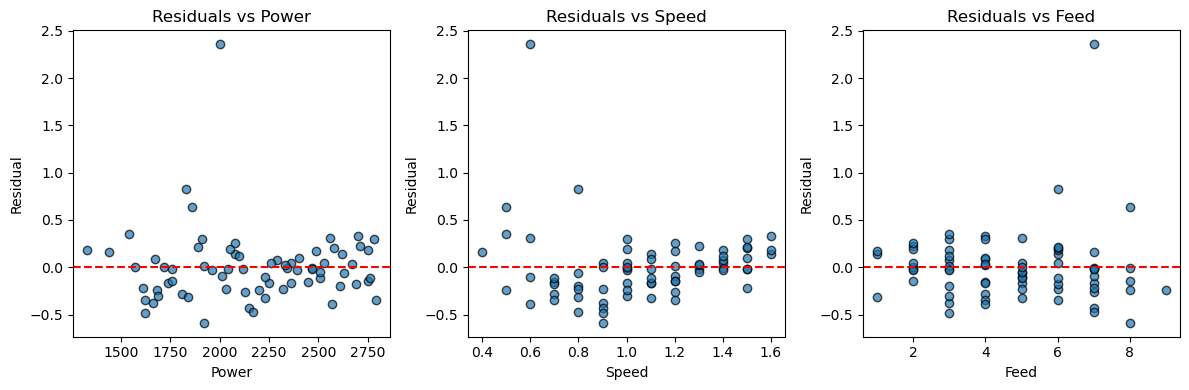

In [37]:
# Residuals vs each predictor (independence check)
fig, axes = plt.subplots(1, len(features), figsize=(4*len(features), 4))

for i, col in enumerate(features):
    axes[i].scatter(X_train[col], residuals_train, alpha=0.7, edgecolors="k")
    axes[i].axhline(0, color="red", linestyle="--")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Residual")
    axes[i].set_title(f"Residuals vs {col}")

plt.tight_layout()
plt.show()



What to look for: No systematic pattern; random scatter around zero for each predictor.

In [38]:
# Statsmodels OLS summary (detailed statistics)
X_train_sm = sm.add_constant(X_train_scaled)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())



                            OLS Regression Results                            
Dep. Variable:             porosity_%   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.409
Method:                 Least Squares   F-statistic:                     17.15
Date:                Fri, 23 Jan 2026   Prob (F-statistic):           2.27e-08
Time:                        01:26:55   Log-Likelihood:                -31.526
No. Observations:                  71   AIC:                             71.05
Df Residuals:                      67   BIC:                             80.10
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3506      0.046      7.607      0.0

This gives you:

p-values for each coefficient (statistical significance).

Adjusted R² (penalises extra features).

F-statistic (overall model significance).

Durbin-Watson (checks autocorrelation in residuals; ~2 is ideal).

Condition number (high values indicate multicollinearity).

In [39]:
# Compile results

results = pd.DataFrame({
    "Metric": ["R²", "RMSE", "MSE", "MAE"],
    "Train": [train_metrics["R2"], train_metrics["RMSE"], train_metrics["MSE"], train_metrics["MAE"]],
    "Test": [test_metrics["R2"], test_metrics["RMSE"], test_metrics["MSE"], test_metrics["MAE"]],
    "CV Mean": [cv_r2.mean(), cv_rmse.mean(), cv_rmse.mean()**2, np.nan]
})
print(results.to_string(index=False))


Metric     Train      Test   CV Mean
    R² -5.134287 -5.134287 -0.640766
  RMSE  0.377224  0.355202  0.362698
   MSE  0.142298  0.126169  0.131550
   MAE  0.227305  0.313244       NaN


# How to interpret results 
| Diagnostic          | What it checks              | Good result               | Action if violated                                               |
| ------------------- | --------------------------- | ------------------------- | ---------------------------------------------------------------- |
| VIF                 | Multicollinearity           | VIF < 5–10                | Drop or combine correlated features                              |
| Residuals vs Fitted | Linearity, homoscedasticity | Random scatter, no funnel | Consider polynomial terms, transformations, or non-linear models |
| Q–Q plot            | Normality of residuals      | Points on diagonal        | Check for outliers; consider robust regression                   |
| Durbin-Watson       | Independence of errors      | Close to 2                | Investigate if data has ordering/time component                  |
| p-values            | Coefficient significance    | p < 0.05                  | Remove non-significant features or justify retention             |